<a href="https://colab.research.google.com/github/SamiNt67/Practica4_IA/blob/main/Copia_de_pr%C3%A1ctica_2_3_teachable_machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Teachable Machine**

En esta práctica se debe exportar el modelo que se genera en Teachable Machine.

A la hora de exportar el modelo, se puede exportar para Tensorflow.

También viene un fragmento de código para usar el modelo:

```
from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model
model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("<IMAGE_PATH>").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

```

**Tarea**: subir 3 imágenes propias (una clara, una ambigua, una que no pertenezca a ninguna categoría) y anotar qué predice y con qué confianza.

**¡Ojo! Hay que cargar una  versión anterior de Keras**

In [3]:
# forzar TensorFlow a usar el comportamiento clásico de Keras 2
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras

print("Versión de TensorFlow:", tf.__version__)
print("Versión de TF-Keras (Legacy):", keras.__version__)

try:
    # Cargamos el modelo utilizando el módulo de compatibilidad oficial tf_keras
    model = keras.models.load_model('keras_model.h5', compile=False)
    print("\n¡MODELO CARGADO CON ÉXITO!")
    model.summary()
except Exception as e:
    print(f"\nError al cargar: {e}")

Versión de TensorFlow: 2.21.0
Versión de TF-Keras (Legacy): 2.21.0

¡MODELO CARGADO CON ÉXITO!
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 1280)              410208    
                                                                 
 sequential_3 (Sequential)   (None, 2)                 128300    
                                                                 
Total params: 538508 (2.05 MB)
Trainable params: 524428 (2.00 MB)
Non-trainable params: 14080 (55.00 KB)
_________________________________________________________________


In [5]:
import tensorflow as tf
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np

class_names = open("labels.txt", "r").readlines()
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
image = Image.open("incidente.png").convert("RGB")
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image)
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

FileNotFoundError: [Errno 2] No such file or directory: 'incidente.png'

In [6]:
#Importar todo
from PIL import Image, ImageOps
import numpy as np
import tensorflow as tf

In [7]:
# implementa la clasificación con la imagen que pertenece claramente a una categoría
# Clasificación con una imagen clara

image = Image.open("logineg.jpg").convert("RGB")

size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

image_array = np.asarray(image)

normalized_image_array = (
    image_array.astype(np.float32) / 127.5
) - 1

data = np.ndarray(
    shape=(1, 224, 224, 3),
    dtype=np.float32
)

data[0] = normalized_image_array

prediction = model.predict(data)

index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

1/1 [==============================] - 1s 985ms/step
Class: Raton
Confidence Score: 0.9999989


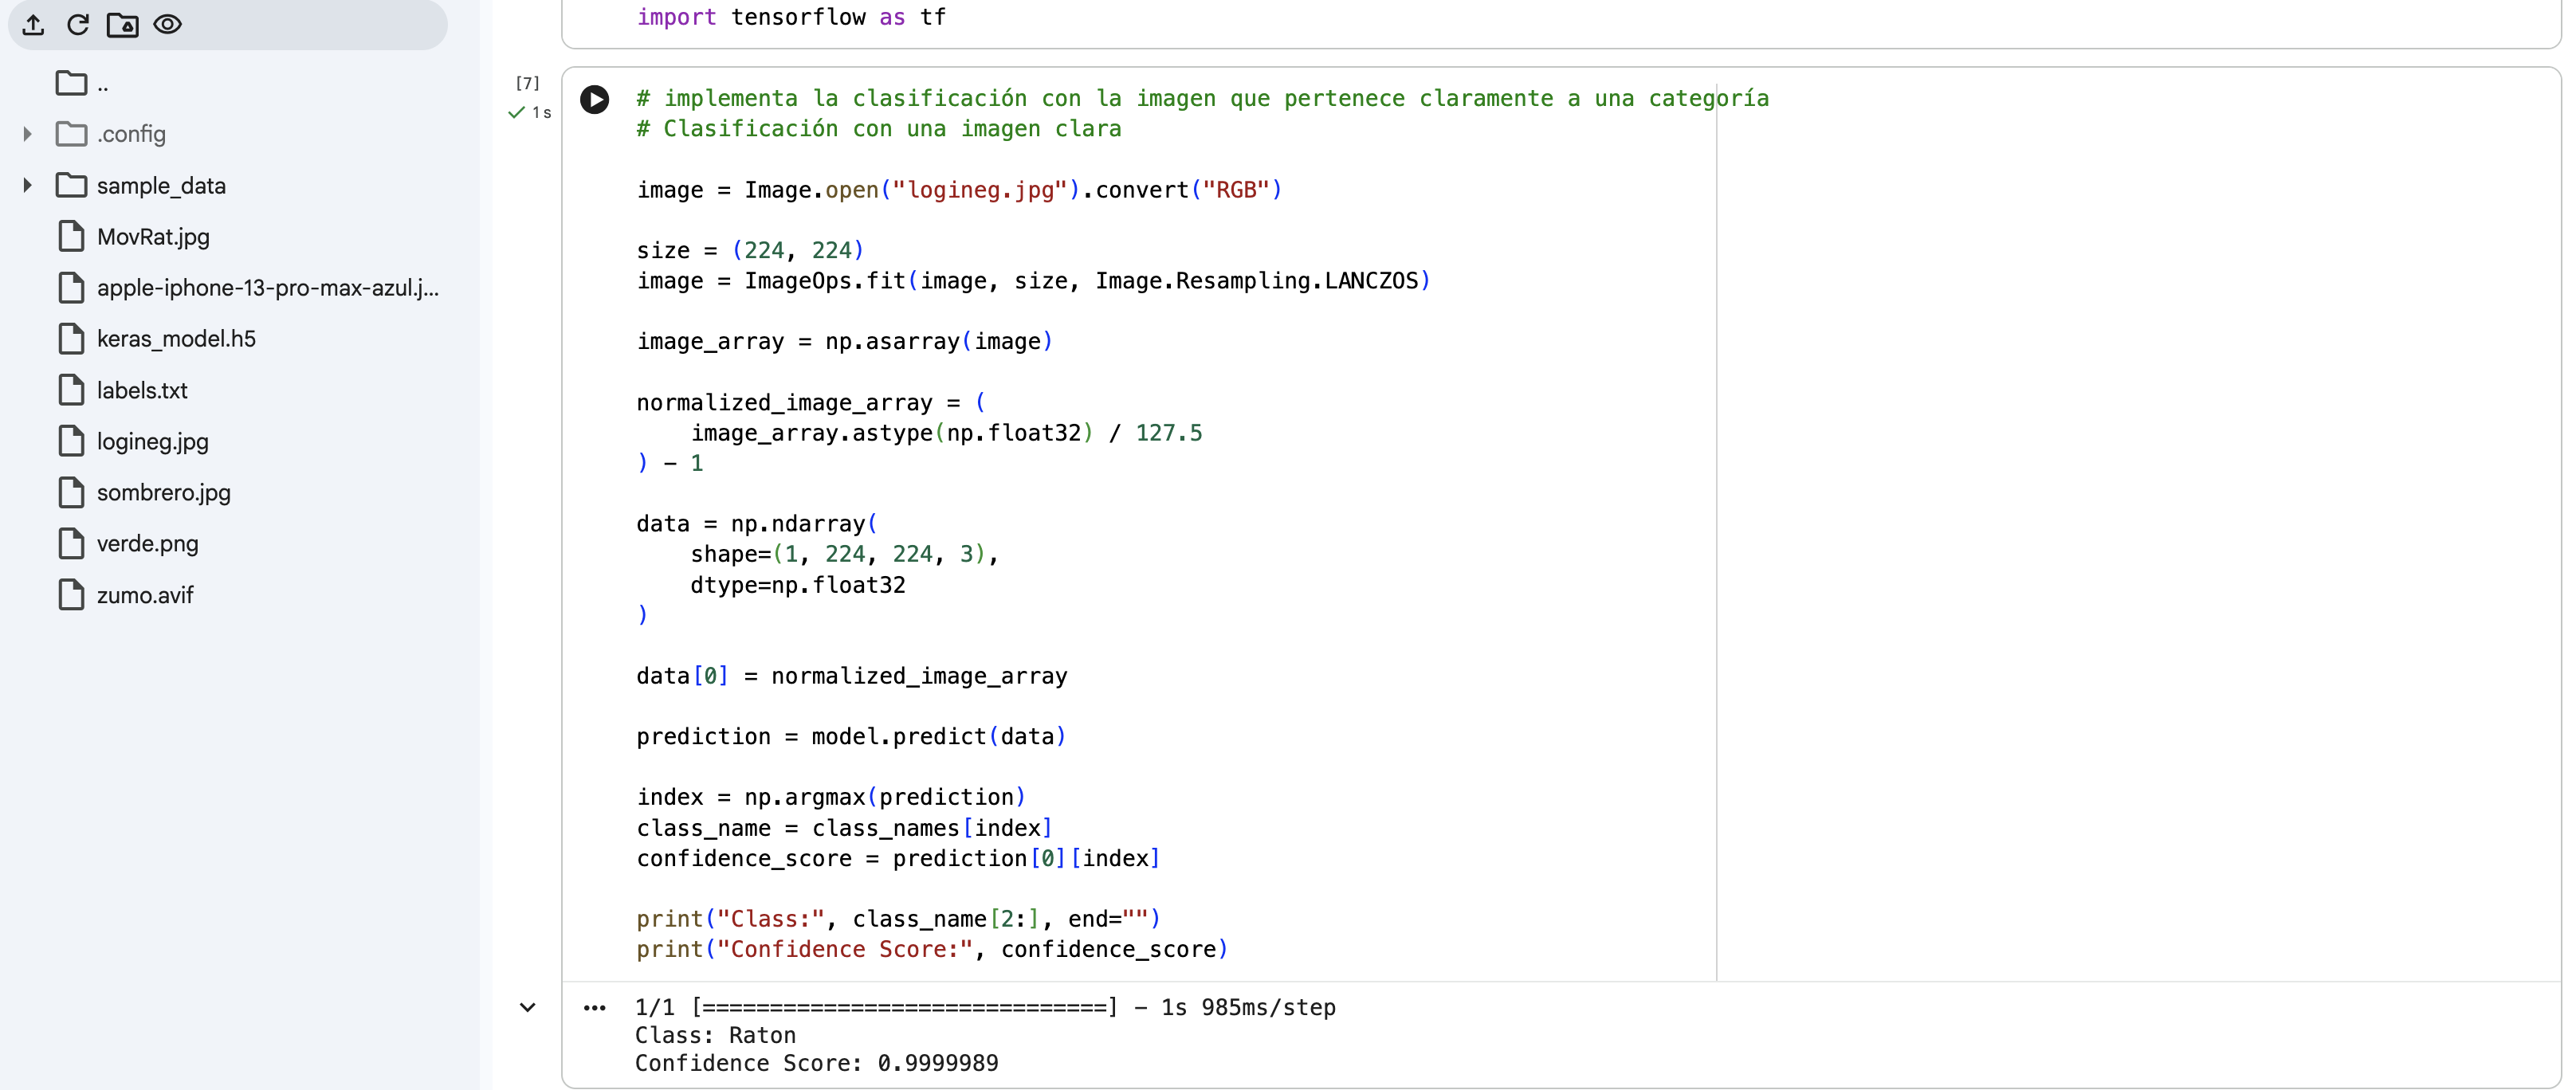

In [13]:
# implementa la clasificación con una imagen ambigua, que puede ser de cualquier categoría
# Clasificación con una imagen ambigua

image = Image.open("MovRat.jpg").convert("RGB")

size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

image_array = np.asarray(image)

normalized_image_array = (
    image_array.astype(np.float32) / 127.5
) - 1

data = np.ndarray(
    shape=(1, 224, 224, 3),
    dtype=np.float32
)

data[0] = normalized_image_array

prediction = model.predict(data)

index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

1/1 [==============================] - 0s 37ms/step
Class: Movil
Confidence Score: 0.9946696


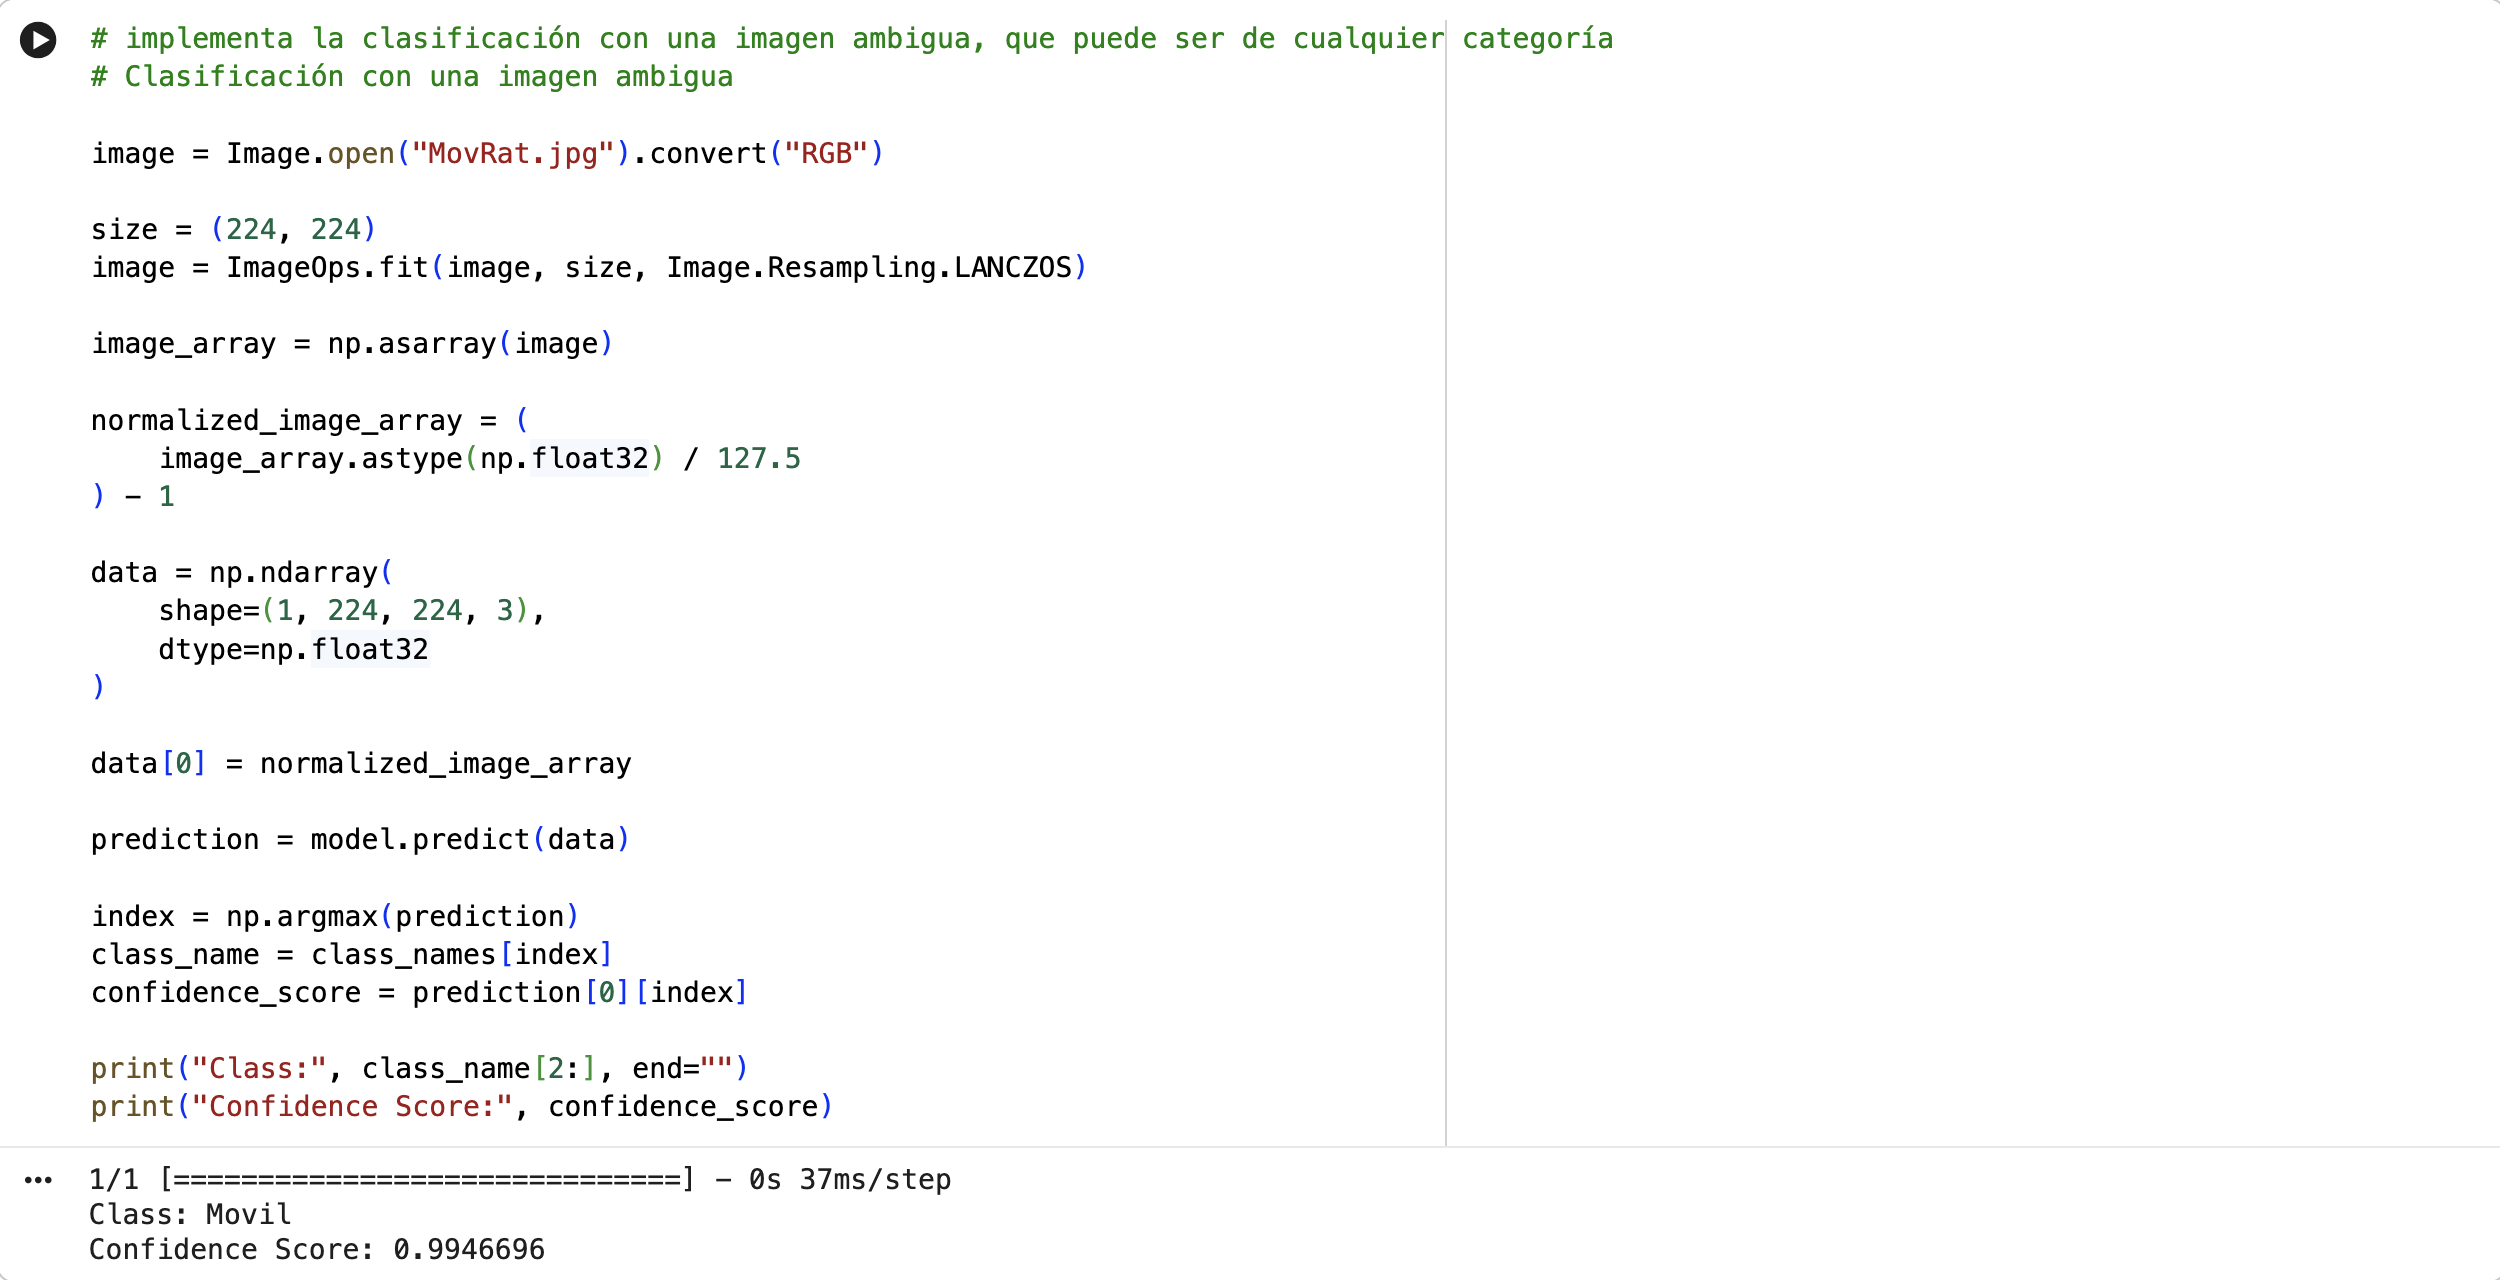

In [12]:
# implementa la clasificación con una imagen sin ninguna categoría del modelo
# Clasificación con una imagen externa

image = Image.open("verde.png").convert("RGB")

size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

image_array = np.asarray(image)

normalized_image_array = (
    image_array.astype(np.float32) / 127.5
) - 1

data = np.ndarray(
    shape=(1, 224, 224, 3),
    dtype=np.float32
)

data[0] = normalized_image_array

prediction = model.predict(data)

index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

1/1 [==============================] - 0s 62ms/step
Class: Raton
Confidence Score: 0.83905303


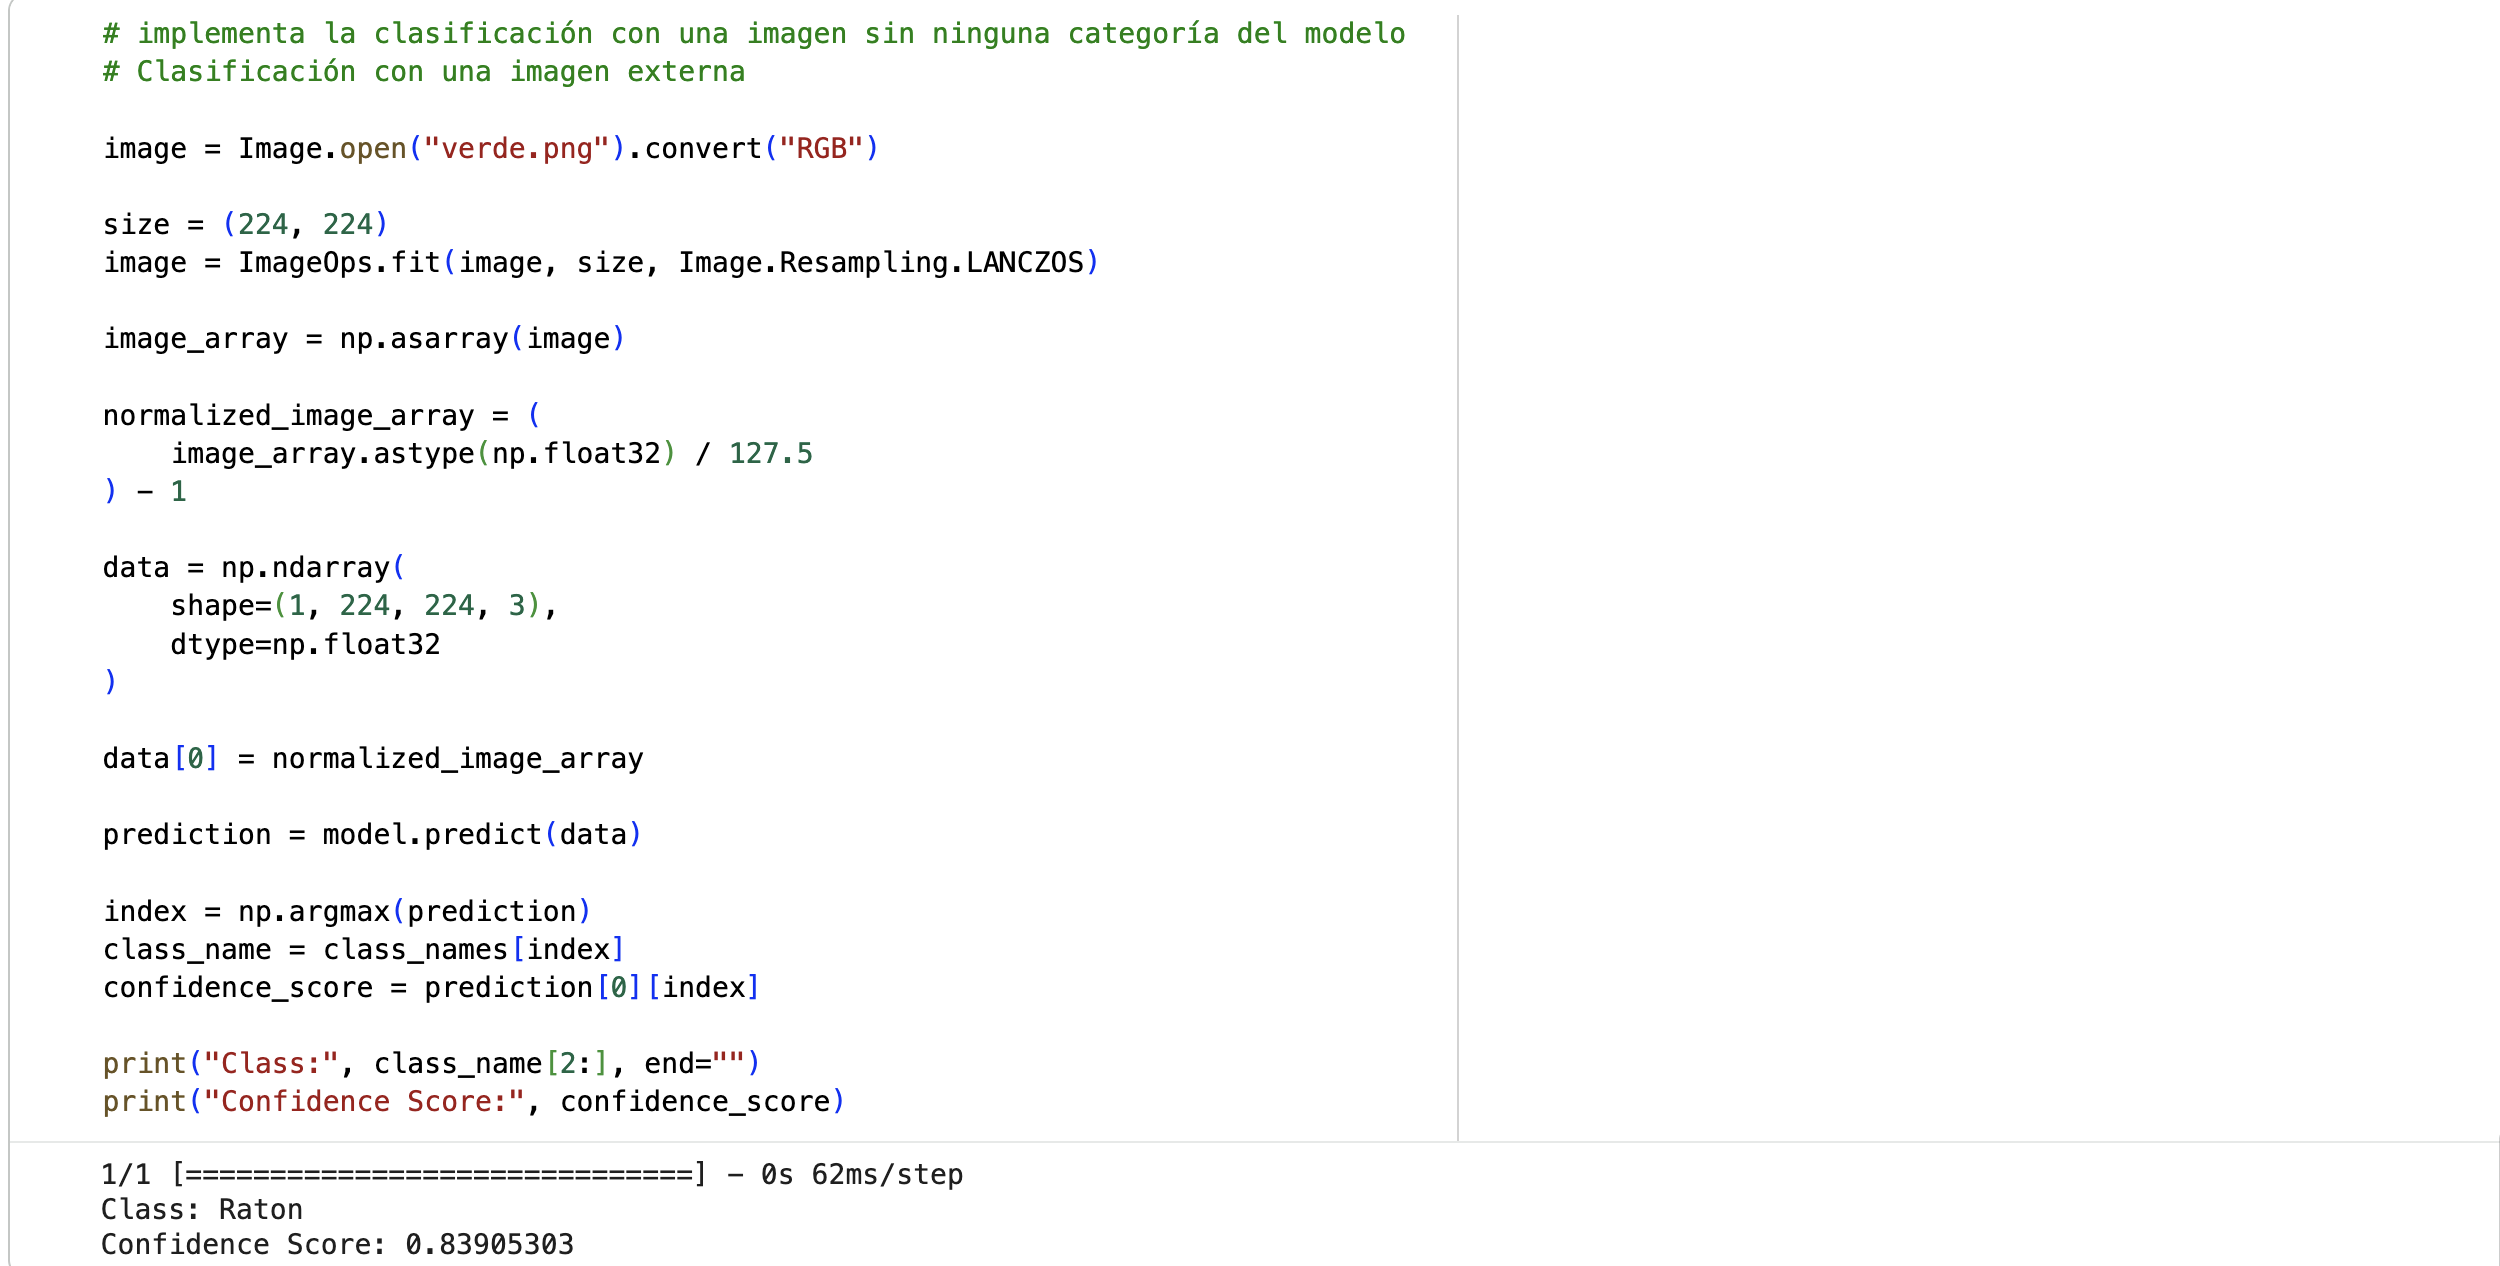

**¿Cómo se usa el modelo exportado? ¿Cómo se comporta?**

---



El modelo exportado se utiliza mediante Python y Keras. Primero se carga el archivo del modelo y sus etiquetas. Después se introduce una imagen, se adapta a un tamaño de 224 × 224 píxeles y se normalizan sus valores para que el modelo pueda procesarla.

A continuación, el modelo realiza una predicción y devuelve la categoría que considera más probable junto con un valor de confianza.

En las pruebas realizadas se observa que con una imagen clara suele reconocer correctamente el objeto y obtener una confianza elevada. Con una imagen ambigua puede confundirse y obtener una confianza errónea, ya que asigna la imágen a un móvil cuando se pueden identificar ambos objetos. Por último, cuando se introduce una imagen que no pertenece a ninguna categoría, el modelo intenta clasificarla dentro de las categorías que conoce, aunque la predicción no sea correcta, pero al menos con un nivel de confianza menor.

En conclusión, el modelo funciona bien con imágenes similares a las que ha utilizado durante su entrenamiento, pero puede cometer errores con imágenes ambiguas o desconocidas.